## Calculate grid for steady state spectrum

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import astropy.units as u
import astropy.constants as const

from scipy.integrate import quad
from tqdm import tqdm

import matplotlib.cm as cm
import matplotlib.colors as mcolors

import h5py

data_dir = "/home/watanabe/Projects/meerkat_bowshocks/meerkat_nrfs/meerkat_nrfs/data/"

Defining constants used in this calculation

In [2]:
# energy parameters
mp = const.m_p.cgs
me = const.m_e.cgs
c = const.c.cgs

# diffusion
delta = 0.5
E0 = 10 * u.GeV
e0 = (E0 / (mp * c**2)).to_value(u.dimensionless_unscaled)
kappa_10 = 3e25 * (u.cm**2 / u.s)

# hadronic loss parameters
sigma_pp = 44 * u.mbarn  # total pion cross section
Kp = 0.5  # inelasticity
mol_weight = 1.4  # mean molecular weight
B_hadr = (c * sigma_pp * Kp / (mp * mol_weight)).cgs  # hadronic loss coefficient
print(f"B_hadr = {B_hadr.cgs:.5e}")

# test parameters
vwind_test = 3000 * (u.km / u.s)
R0_test = 1 * u.pc
rho0_test = 2e-25 * (u.g / u.cm**3)

B_hadr = 2.81655e+08 cm3 / (g s)


Generate grid of energies used in this calculation. 

In [3]:
# grid of energies from 1 GeV to 10 TeV
Ekin_arr = np.logspace(np.log10(1.3), 4, 100) * u.GeV  
ekin_arr = (Ekin_arr / (mp * c**2)).to_value(u.dimensionless_unscaled)
print(ekin_arr.min(), ekin_arr.max())

1.385525602225563 10657.889247888947


Computing the greens function

In [4]:
def tau_crdiff(ekin, kappa_10, R0):
    '''Diffusion timescale'''
    kk = R0**2 / kappa_10 * e0**delta
    return (kk * ekin**(-delta)).to_value(u.s)

def tau_cradv(R0, v):
    '''ADvection timescale'''
    return (R0 / v).to_value(u.s)

def b_hadr(ekin, rho):
    return (B_hadr * rho * ekin).to_value(u.s**-1)

def greens_integrand(e, kappa_10, v, R0, rho):
    return (tau_cradv(R0, v)**-1 + tau_crdiff(e, kappa_10, R0)**-1) * b_hadr(e, rho)**-1

In [8]:
green_int_test = np.zeros((len(ekin_arr), len(ekin_arr)))

for i, e in enumerate(ekin_arr):
    for j, ep in enumerate(ekin_arr):
        greens_integral, _ = quad(greens_integrand, e, ep, args=(kappa_10, vwind_test, R0_test, rho0_test))
        green_int_test[i,j] = greens_integral 

In [8]:
# analytical model
green_int_thr = np.zeros((len(ekin_arr), len(ekin_arr)))
for ie, e in enumerate(ekin_arr):
    green_int_thr[ie,:] =  ((B_hadr * rho0_test).to_value(u.s**-1))**-1 * (((R0_test / vwind_test).to_value(u.s))**-1 * np.log(ekin_arr / e) + ((R0_test**2 / kappa_10 * e0**delta).to_value(u.s))**-1 / delta * (ekin_arr**delta - e**delta) )

Text(0.5, 1.0, '$\\kappa_{10}$ = 3e+25 cm2 / s, $v_w$ = 3000 km / s, $R_0$ = 1.00 pc, $E / (mc^2)$ = 2.9 GeV, $\\rho$ = 2.00e-25 g / cm3')

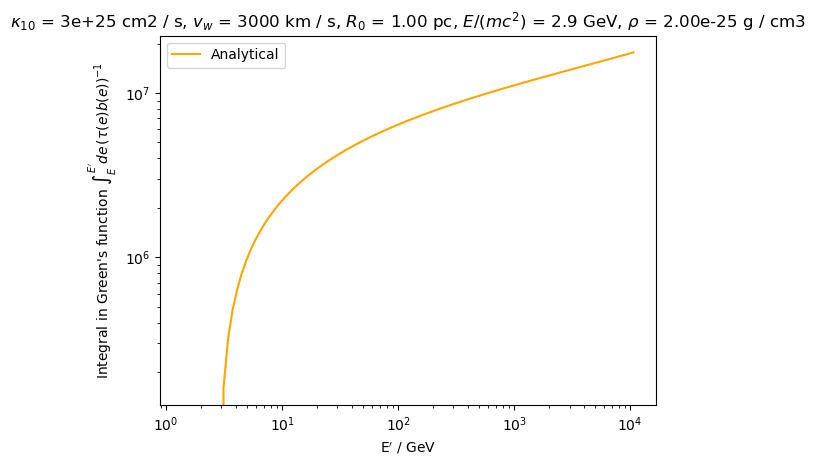

In [10]:
# plt.loglog(ekin_arr, green_int_test[8,:], label="Numerical", marker="o")
plt.loglog(ekin_arr, green_int_thr[8,:], label="Analytical", color="orange")
plt.legend()

plt.xlabel(r"E$^\prime$ / GeV")
plt.ylabel(r"Integral in Green's function $\int_{E}^{E^\prime} de \, (\tau(e) b(e))^{-1}$")
plt.title(rf"$\kappa_{{10}}$ = {kappa_10:.0e}, $v_w$ = {vwind_test:.0f}, $R_0$ = {R0_test:.2f}, $E / (mc^2)$ = {ekin_arr[8]:.1f} GeV, $\rho$ = {rho0_test:.2e}")

Text(0, 0.5, 'G(E, E$^\\prime$)')

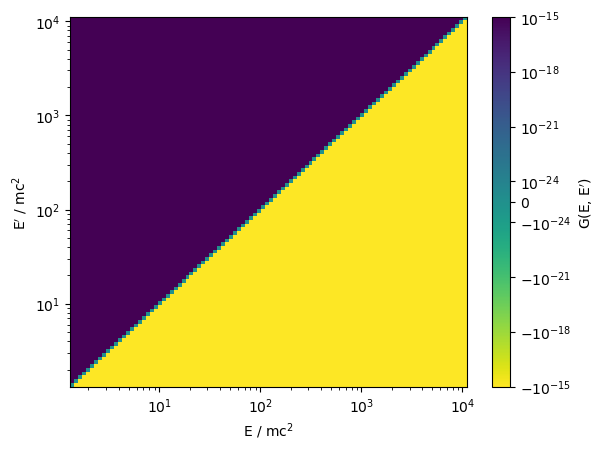

In [11]:
EE, EEP = np.meshgrid(ekin_arr, ekin_arr, indexing="ij")

norm = mcolors.SymLogNorm(linthresh=1e-24, vmin=-1e-15, vmax=1e-15)
pc = plt.pcolormesh(EE, EEP, green_int_thr, norm=norm, cmap=cm.viridis_r)

plt.xlabel("E / mc$^2$")
plt.ylabel("E$^\prime$ / mc$^2$")
plt.xscale("log")
plt.yscale("log")
cbar = plt.colorbar(pc)
cbar.ax.set_ylabel("G(E, E$^\prime$)")

DEfine injection spectrum and get steady state spectrum

In [12]:
def inj_spect(ep, alpha_inj):
    '''Unnormalised injection spectrum, unitless'''
    return (ep**2 - 1)**(-0.5 * (alpha_inj + 1)) * ep

alpha_inj_grid = np.linspace(4, 10, 50)
inj_spectrum_grid = np.zeros((len(ekin_arr), len(alpha_inj_grid)))

for ia, alpha_inj in enumerate(alpha_inj_grid):
    inj_spectrum_grid[:,ia] = inj_spect(ekin_arr, alpha_inj)

In [13]:
steady_state_grid = np.zeros((len(ekin_arr), len(alpha_inj_grid)))

for ia, alpha_inj in enumerate(alpha_inj_grid):
    for ie, ekin in enumerate(ekin_arr):
        steady_state_grid[ie, ia] = np.trapz(y=inj_spectrum_grid[ie:,ia] * (B_hadr * ekin_arr[ie:] * rho0_test).to_value(u.s**-1)**-1 * np.exp(-green_int_thr[ie,ie:]), x=ekin_arr[ie:])

Text(0.5, 1.0, '$\\kappa_{10}$ = 3e+25 cm2 / s, $v_w$ = 3000 km / s, $R_0$ = 1.00 pc, $\\alpha$ = 4.2')

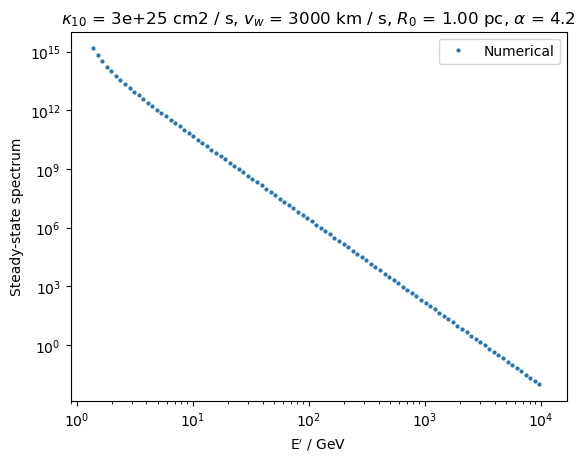

In [15]:
plt.loglog(ekin_arr, steady_state_grid[:,2], label="Numerical", marker="o", ls="", ms=2.0)
plt.legend()

plt.xlabel(r"E$^\prime$ / GeV")
plt.ylabel(r"Steady-state spectrum")
plt.title(rf"$\kappa_{{10}}$ = {kappa_10:.0e}, $v_w$ = {vwind_test:.0f}, $R_0$ = {R0_test:.2f}, $\alpha$ = {alpha_inj_grid[2]:.1f}")

log10_enratio

In [16]:
def mom(e):
    return mp * c * np.sqrt(e**2 - 1)

steady_state_mom_grid = steady_state_grid * mom(ekin_arr[:,None]) / (mp * ekin_arr[:,None])  # for the factor of dE / dp

Text(0.5, 1.0, '$\\kappa_{10}$ = 3e+25 cm2 / s, $v_w$ = 3000 km / s, $R_0$ = 1.00 pc, $\\alpha$ = 4.2')

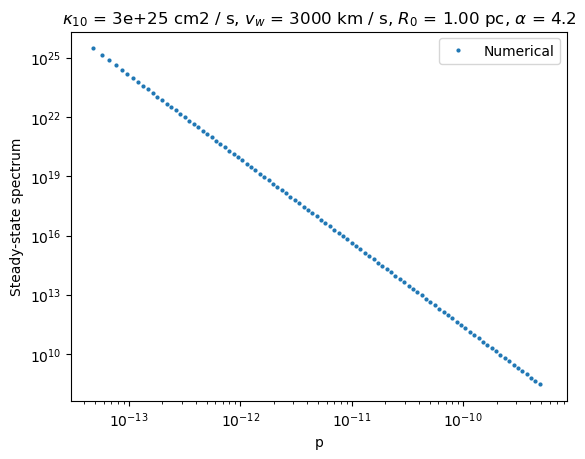

In [17]:
plt.loglog(mom(ekin_arr), steady_state_mom_grid[:,2], label="Numerical", marker="o", ls="", ms=2.0)
plt.legend()

plt.xlabel(r"p")
plt.ylabel(r"Steady-state spectrum")
plt.title(rf"$\kappa_{{10}}$ = {kappa_10:.0e}, $v_w$ = {vwind_test:.0f}, $R_0$ = {R0_test:.2f}, $\alpha$ = {alpha_inj_grid[2]:.1f}")

In [18]:
ncr_grid = np.trapz(y=4 * np.pi * mom(ekin_arr[:,None])**2 * steady_state_mom_grid, x=mom(ekin_arr), axis=0)
encr_grid = np.trapz(y=4 * np.pi * mom(ekin_arr[:,None])**2 * ekin_arr[:,None] * steady_state_mom_grid, x=mom(ekin_arr), axis=0)

log10_enratio_grid = np.log10(((encr_grid * mp * c**2) / ncr_grid).to_value(u.GeV))

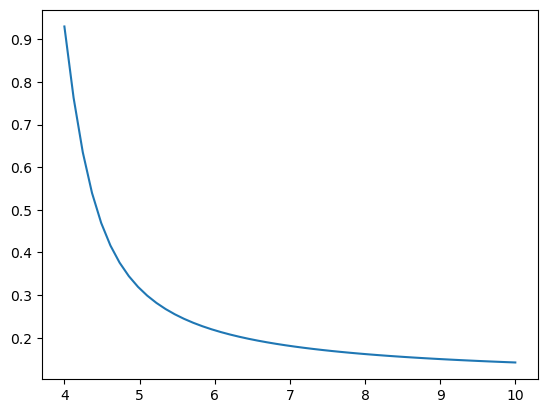

In [19]:
plt.plot(alpha_inj_grid, log10_enratio_grid)

## Now do the same and create grid of values instead


In [40]:
R0_min = 1e-3 * u.pc
R0_max = 5 * u.pc
vmin = 1e-2 * (u.km/u.s)
vmax = 5e3 * (u.km/u.s)

vel_grid = np.logspace(np.log10(vmin.value), np.log10(vmax.value), 10) * (u.km/u.s)
R0_grid = np.logspace(np.log10(R0_min.value), np.log10(R0_max.value), 10) * u.pc
kappa_10_grid = np.logspace(np.log10(3e22), np.log10(3e28), 10)  * (u.cm**2 / u.s)
dens_grid = np.logspace(np.log10(1e-30), np.log10(1e-19), 10) * (u.g / u.cm**3)

green_int_grid = np.zeros((len(ekin_arr), len(ekin_arr), len(kappa_10_grid), len(R0_grid), len(vel_grid), len(dens_grid)))

for (ik, ir, iv, id) in np.ndindex((len(kappa_10_grid), len(R0_grid), len(vel_grid), len(dens_grid))):

    R0 = R0_grid[ir].cgs.value
    kappa_10 = kappa_10_grid[ik].cgs.value
    vel = vel_grid[iv].cgs.value
    rho = dens_grid[id].cgs

    tau_adv = R0 / vel
    taudiff_coeff =  (R0**2 / kappa_10 * e0**delta)
    bhadr_coeff = (B_hadr * rho).cgs.value

    # analytical function
    for ie, e in enumerate(ekin_arr):
        green_int_grid[ie,:,ik,ir,iv,id] = bhadr_coeff**-1 * (tau_adv**-1 * np.log(ekin_arr / e) + taudiff_coeff**-1 / (delta) * (ekin_arr**(delta) - e**(delta )) )

KeyboardInterrupt: 

In [ ]:
alpha_inj_grid = np.linspace(4, 10, 25)

steady_state_grid = np.zeros((len(ekin_arr), len(alpha_inj_grid), len(kappa_10_grid), len(R0_grid), len(vel_grid), len(dens_grid)))

for ia in tqdm(range(len(alpha_inj_grid)), desc="Computing steady state spectrum over alpha_inj", total=len(alpha_inj_grid)):
    alpha_inj = alpha_inj_grid[ia]

    inj_spectrum_grid = inj_spect(ekin_arr, alpha_inj)[:,None,None,None]

    for id, rho in enumerate(dens_grid):
        bhadr = ((B_hadr * rho).to_value(u.s**-1) * ekin_arr)[:,None,None,None]

        for ie, e in enumerate(ekin_arr):
            steady_state_grid[ie,ia,:,:,:,id] = np.trapz(inj_spectrum_grid[ie:,...] * bhadr[ie:,...]**-1 * np.exp(-green_int_grid[ie,ie:,...,id]), x=ekin_arr[ie:], axis=0)

Computing steady state spectrum over alpha_inj: 100%|██████████| 25/25 [00:30<00:00,  1.21s/it]


In [ ]:
def mom(e):
    return mp * c * np.sqrt(e**2 - 1)

steady_state_mom_grid = steady_state_grid * mom(ekin_arr[:,None,None,None,None,None]) / (mp * ekin_arr[:,None,None,None,None,None])  # for the factor of dE / dp
ncr_grid = np.trapz(y=4 * np.pi * mom(ekin_arr[:,None,None,None,None,None])**2 * steady_state_mom_grid, x=mom(ekin_arr), axis=0)
encr_grid = np.trapz(y=4 * np.pi * mom(ekin_arr[:,None,None,None,None,None])**2 * ekin_arr[:,None,None,None,None,None] * steady_state_mom_grid, x=mom(ekin_arr), axis=0)

log10_enratio_grid = np.log10(((encr_grid * mp * c**2) / ncr_grid).to_value(u.GeV))

In [37]:
with h5py.File(f"{data_dir}/steady_state_spectrum_thr.h5", "w") as f:
    f.create_dataset("alpha_inj_grid", data=alpha_inj_grid)
    f.create_dataset("log10_R0_grid", data=np.log10(R0_grid.value))
    f.create_dataset("log10_vel_grid", data=np.log10(vel_grid.value))
    f.create_dataset("log10_kappa10_grid", data=np.log10(kappa_10_grid.value))
    f.create_dataset("log10_dens_grid", data=np.log10(dens_grid.value))
    f.create_dataset("log10_pprot_grid", data=np.log10(mom(ekin_arr).value))
    f.create_dataset("steady_spect_grid", data=steady_state_grid)
    f.create_dataset("steady_spect_mom_grid", data=steady_state_mom_grid)
    f.create_dataset("log10_enratio_grid", data=log10_enratio_grid)